In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('Travel.csv')

In [3]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [5]:
import warnings
from warnings import filterwarnings
filterwarnings("ignore")

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.shape

(4888, 20)

In [8]:
df['ProdTaken'].value_counts()

ProdTaken
0    3968
1     920
Name: count, dtype: int64

In [9]:
df.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                         float64
TypeofContact                object
CityTier                      int64
DurationOfPitch             float64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched               object
PreferredPropertyStar       float64
MaritalStatus                object
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                  object
MonthlyIncome               float64
dtype: object

In [10]:
cat=df.select_dtypes('object')

In [11]:
cat.head()

,TypeofContact,Occupation,Gender,ProductPitched,MaritalStatus,Designation
0,Self Enquiry,Salaried,Female,Deluxe,Single,Manager
1,Company Invited,Salaried,Male,Deluxe,Divorced,Manager
2,Self Enquiry,Free Lancer,Male,Basic,Single,Executive
3,Company Invited,Salaried,Female,Basic,Divorced,Executive
4,Self Enquiry,Small Business,Male,Basic,Divorced,Executive


In [12]:
df['Gender']=df['Gender'].replace("Fe Male","Female")

In [13]:
df['MaritalStatus']=df['MaritalStatus'].replace("Single","Unmarried")

In [14]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Unmarried    1598
Divorced      950
Name: count, dtype: int64

In [15]:
df['Occupation'].value_counts()

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64

In [16]:
# handle null values
# find features of null values

In [17]:
null=[features for features in df.columns if df[features].isnull().sum()>=1]

In [18]:
null

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [19]:
for features in null:
    print(features,np.round(df[features].isnull().mean()*100,2))

Age 4.62
TypeofContact 0.51
DurationOfPitch 5.14
NumberOfFollowups 0.92
PreferredPropertyStar 0.53
NumberOfTrips 2.86
NumberOfChildrenVisiting 1.35
MonthlyIncome 4.77


In [20]:
df[null].select_dtypes(exclude='object').describe()

,Age,DurationOfPitch,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,NumberOfChildrenVisiting,MonthlyIncome
count,4662.000000,4637.000000,4843.000000,4862.000000,4748.000000,4822.000000,4655.000000
mean,37.622265,15.490835,3.708445,3.581037,3.236521,1.187267,23619.853491
std,9.316387,8.519643,1.002509,0.798009,1.849019,0.857861,5380.698361
min,18.000000,5.000000,1.000000,3.000000,1.000000,0.000000,1000.000000
25%,31.000000,9.000000,3.000000,3.000000,2.000000,1.000000,20346.000000
50%,36.000000,13.000000,4.000000,3.000000,3.000000,1.000000,22347.000000
75%,44.000000,20.000000,4.000000,4.000000,4.000000,2.000000,25571.000000
max,61.000000,127.000000,6.000000,5.000000,22.000000,3.000000,98678.000000


In [21]:
df[null].columns

Index(['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome'],
      dtype='object')

In [22]:
columns=['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome']

In [23]:
df_num=df[null][columns].select_dtypes('float64','int64')

In [24]:
df_num

,Age,DurationOfPitch,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,NumberOfChildrenVisiting,MonthlyIncome
0,41.0,6.0,3.0,3.0,1.0,0.0,20993.0
1,49.0,14.0,4.0,4.0,2.0,2.0,20130.0
2,37.0,8.0,4.0,3.0,7.0,0.0,17090.0
3,33.0,9.0,3.0,3.0,2.0,1.0,17909.0
4,NaN,8.0,3.0,4.0,1.0,0.0,18468.0
...,...,...,...,...,...,...,...
4883,49.0,9.0,5.0,4.0,2.0,1.0,26576.0
4884,28.0,31.0,5.0,3.0,3.0,2.0,21212.0
4885,52.0,17.0,4.0,4.0,7.0,3.0,31820.0
4886,19.0,16.0,4.0,3.0,3.0,2.0,20289.0


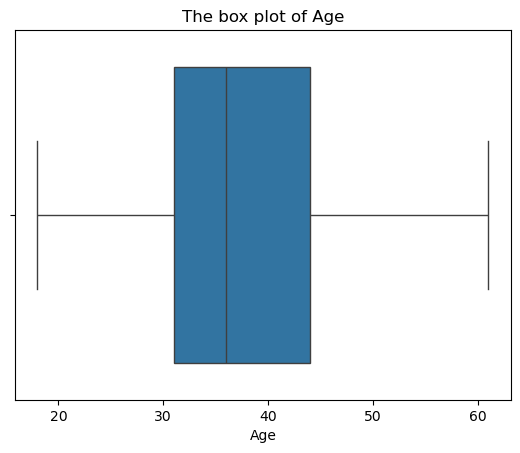

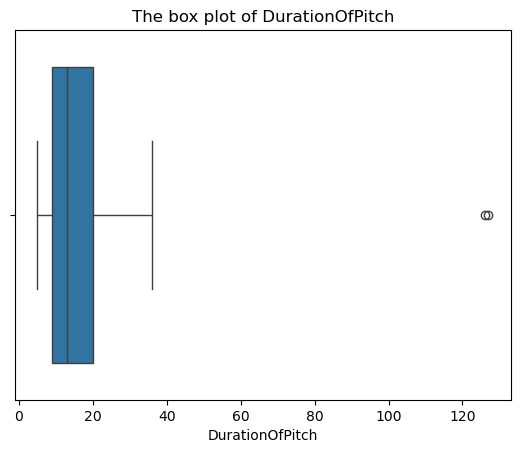

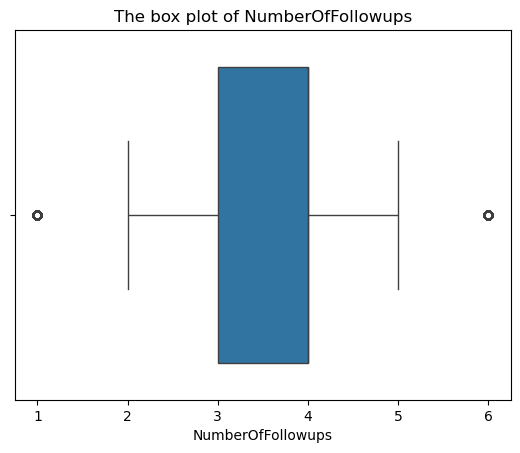

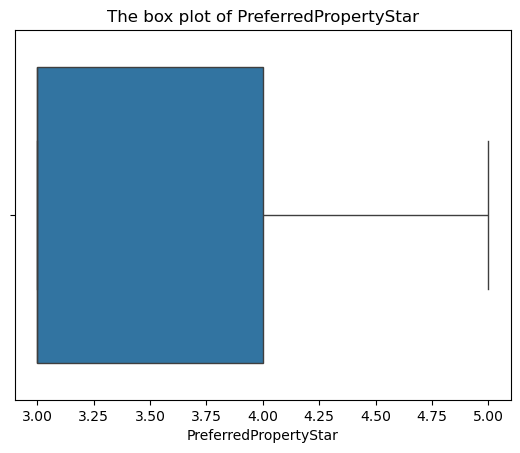

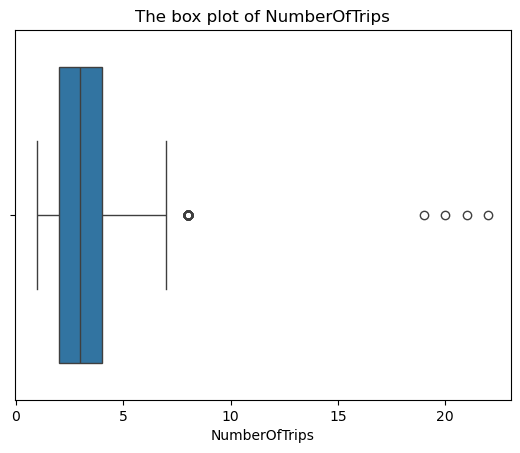

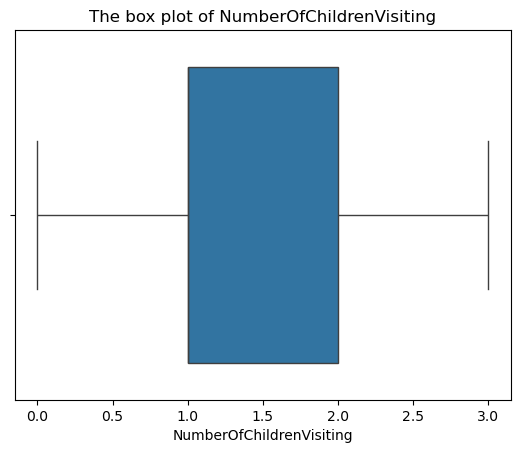

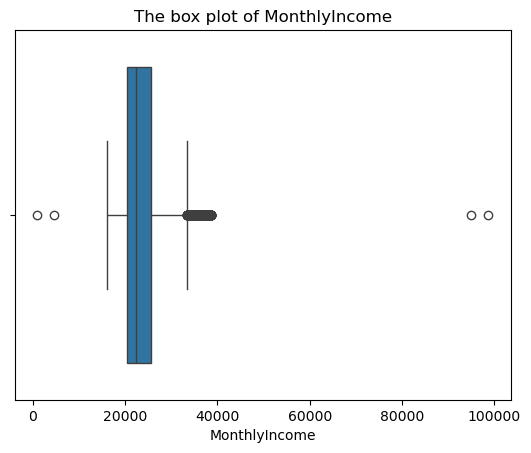

In [25]:
for col in df_num.columns:
    plt.figure()
    sns.boxplot(x=df_num[col])
    plt.title(f'The box plot of {col}')

In [26]:
df['Age']=df['Age'].fillna(df['Age'].mean())
df['TypeofContact']=df['TypeofContact'].fillna(df['TypeofContact'].mode().iloc[0])
df['NumberOfFollowups']=df['NumberOfFollowups'].fillna(df['NumberOfFollowups'].median())
df['DurationOfPitch']=df['DurationOfPitch'].fillna(df['DurationOfPitch'].median())
df['PreferredPropertyStar']=df['PreferredPropertyStar'].fillna(df['PreferredPropertyStar'].mean())
df['NumberOfTrips']=df['NumberOfTrips'].fillna(df['NumberOfTrips'].median())
df['NumberOfChildrenVisiting']=df['NumberOfChildrenVisiting'].fillna(df['NumberOfChildrenVisiting'].mean())
df['MonthlyIncome']=df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())


In [27]:
df.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [28]:
df.drop('CustomerID',inplace=True,axis=1)

In [29]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

#  Feature Engineering


In [30]:
df["Total_Visiting"]=df['NumberOfPersonVisiting']+ df["NumberOfChildrenVisiting"]

In [31]:
df.drop(columns=["NumberOfChildrenVisiting","NumberOfPersonVisiting"],inplace=True)

In [32]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfFollowups', 'ProductPitched',
       'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'Designation', 'MonthlyIncome',
       'Total_Visiting'],
      dtype='object')

In [33]:
# model training and train test split

In [34]:
X=df.drop("ProdTaken",axis=1)
y=df['ProdTaken']

In [35]:
X.columns

Index(['Age', 'TypeofContact', 'CityTier', 'DurationOfPitch', 'Occupation',
       'Gender', 'NumberOfFollowups', 'ProductPitched',
       'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'Designation', 'MonthlyIncome',
       'Total_Visiting'],
      dtype='object')

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [38]:
# column transformer = used to apply different preprocessing tech to different column of dataset

In [39]:
from sklearn.compose import ColumnTransformer

In [40]:
cat_fea=X.select_dtypes(include='object').columns
num_fea=X.select_dtypes(exclude='object').columns

In [41]:
cat_fea

Index(['TypeofContact', 'Occupation', 'Gender', 'ProductPitched',
       'MaritalStatus', 'Designation'],
      dtype='object')

In [42]:
num_fea

Index(['Age', 'CityTier', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'MonthlyIncome', 'Total_Visiting'],
      dtype='object')

In [43]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [44]:
# Create an object of both priprocessing 

In [45]:
oe=OneHotEncoder()
ss=StandardScaler()

In [46]:
preprocessor=ColumnTransformer([
    ("OneHotEncoder",oe,cat_fea),
    ("StandardScaler",ss,num_fea)
]
)

In [47]:
# Apply transformation in training data and testing data

In [48]:
X_train=preprocessor.fit_transform(X_train)

In [49]:
X_test=preprocessor.transform(X_test)

In [50]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score, precision_score, recall_score

In [51]:
models={
    "RF":RandomForestClassifier(),
    "DT":DecisionTreeClassifier(),
    "ADA":AdaBoostClassifier(),
    "GB":GradientBoostingClassifier(),
    "XG":XGBClassifier()
}

In [52]:
for i in range (len(list(models))):
    model=list(models.values())[i]

    # model training 
    model.fit(X_train,y_train)

    # model prediction
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)

    print(list(models.values())[i])

# checking accuracy
    print("Training accuracy")
    print(f"accuracy={accuracy_score(y_train,y_train_pred)}")
    print(f"precision={precision_score(y_train,y_train_pred)}")
    print(f"recall={recall_score(y_train,y_train_pred)}")
    print(f"f1 score={f1_score(y_train,y_train_pred)}")

# check test accura
    print("Testing accuracy")
    print(f"accuracy={accuracy_score(y_test,y_test_pred)}")
    print(f"precision={precision_score(y_test,y_test_pred)}")
    print(f"recall={recall_score(y_test,y_test_pred)}")
    print(f"f1 score={f1_score(y_test,y_test_pred)}")

    print("---------------------------------------------------")

RandomForestClassifier()
Training accuracy
accuracy=1.0
precision=1.0
recall=1.0
f1 score=1.0
Testing accuracy
accuracy=0.9233128834355828
precision=0.9603174603174603
recall=0.6335078534031413
f1 score=0.7634069400630915
---------------------------------------------------
DecisionTreeClassifier()
Training accuracy
accuracy=1.0
precision=1.0
recall=1.0
f1 score=1.0
Testing accuracy
accuracy=0.9161554192229039
precision=0.7978142076502732
recall=0.7643979057591623
f1 score=0.7807486631016043
---------------------------------------------------
AdaBoostClassifier()
Training accuracy
accuracy=0.8506393861892583
precision=0.7935222672064778
recall=0.26886145404663925
f1 score=0.4016393442622951
Testing accuracy
accuracy=0.8404907975460123
precision=0.7868852459016393
recall=0.2513089005235602
f1 score=0.38095238095238093
---------------------------------------------------
GradientBoostingClassifier()
Training accuracy
accuracy=0.8936061381074168
precision=0.8735083532219571
recall=0.5020576

In [53]:
# Hyper Parameter Tuning 

In [54]:
rf_params={
    "max_depth":[5,8,10,15,20],
    "max_feature":[5,7,"auto",8],
    "min_sample_leaf":[2,8,15,20],
    "n_estimators":[100,200,500,1000]
}

In [55]:
# randomcv_model

In [56]:
random_models=[
    ("RF",RandomForestClassifier(),rf_params)
]

In [57]:
from sklearn.model_selection import RandomizedSearchCV

In [58]:
random_models

[('RF',
  RandomForestClassifier(),
  {'max_depth': [5, 8, 10, 15, 20],
   'max_feature': [5, 7, 'auto', 8],
   'min_sample_leaf': [2, 8, 15, 20],
   'n_estimators': [100, 200, 500, 1000]})]

In [59]:
xgb_params={
    "n_estimators":[100,200,500,1000],
    "max_depth":[3,5,7,10],
    "learning_rate":[0.01,0.05,0.1,0.2]
}

In [60]:
from xgboost import XGBClassifier

In [ ]:
xgb_model=XGBClassifier(
    objective="binary:logistic",
    evaluation_metric="logloss",
    use_label_encoder=False
)

In [65]:
best_para=RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_params,
    cv=5,
    random_state=42
)

In [66]:
best_para.fit(X_train,y_train)

,estimator,"XGBClassifier...obs=None, ...)"
,param_distributions,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...]}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [67]:
best_para.best_params_

{'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.2}

In [68]:
best_para.best_score_

np.float64(0.9329923273657288)

In [71]:
models={
    "XG boost":XGBClassifier()
}

In [72]:
for i in range (len(list(models))):
    model=list(models.values())[i]

    # model training 
    model.fit(X_train,y_train)

    # model prediction
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)

    print(list(models.values())[i])

# checking accuracy
    print("Training accuracy")
    print(f"accuracy={accuracy_score(y_train,y_train_pred)}")
    print(f"precision={precision_score(y_train,y_train_pred)}")
    print(f"recall={recall_score(y_train,y_train_pred)}")
    print(f"f1 score={f1_score(y_train,y_train_pred)}")

# check test accura
    print("Testing accuracy")
    print(f"accuracy={accuracy_score(y_test,y_test_pred)}")
    print(f"precision={precision_score(y_test,y_test_pred)}")
    print(f"recall={recall_score(y_test,y_test_pred)}")
    print(f"f1 score={f1_score(y_test,y_test_pred)}")

    print("---------------------------------------------------")

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)
Training accuracy
accuracy=0.9997442455242966
precision=1.0
recall=0.9986282578875172
f1 score=0.9993136582017845
Testing accuracy
accuracy=0.9468302658486708
precision=0.954248366013072
recall=0.7643979057591623
f1 score=0.8488372093023255

In [73]:
import joblib

In [74]:
preprocess_job=joblib.dump(preprocessor,'preprocessor.joblib')

In [75]:
joblib.dump(models,'model.joblib')

['model.joblib']